In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:

df = pd.read_csv("../data/interim/listings_parsed_v6.csv")
print(len(df))   # expect 183490

183490


In [3]:
df["is_ward"] = df["municipality"].str.endswith("区").astype(int)
df["region"] = df["municipality"].map(
    lambda x: "ward" if x.endswith("区") else ("city" if x.endswith("市") else "town_village"))

In [4]:
df.to_csv("../data/interim/listings_parsed_v7.csv", index=False)

In [5]:
cols = ["Price_yen", "area_m2", "age_years", "is_new", "floor_min", "stories_above",
        "walk_min_nearest", "municipality", "n_rooms"]
df = pd.read_csv("../data/interim/listings_parsed_v7.csv", usecols=cols)

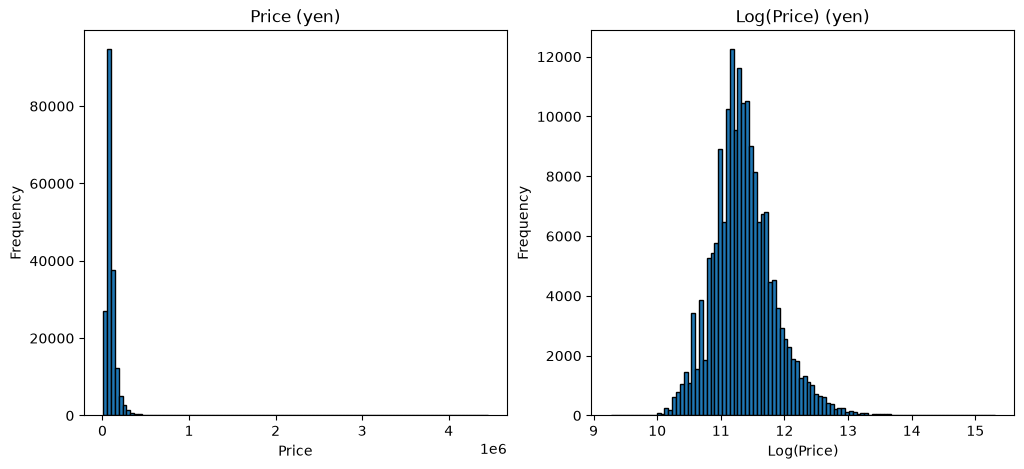

In [6]:
# histogram of price_yen and np.log(price_yen) to see if log transform is needed using matplotlib 
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df["Price_yen"], bins=100, edgecolor='black')
plt.title("Price (yen)")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(np.log(df["Price_yen"]), bins=100, edgecolor='black')
plt.title("Log(Price) (yen)")
plt.xlabel("Log(Price)")
plt.ylabel("Frequency")

plt.show()

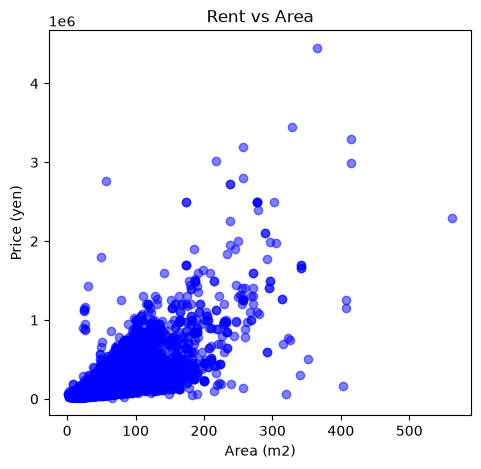

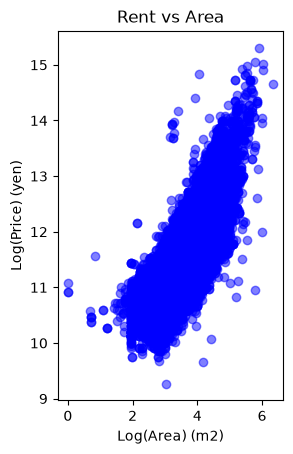

In [7]:
# Rent Vs Area Scatter plot to see if there is a linear relationship between area_m2 and Price_yen, also do log-log comparison, alpha=0.5, color='blue'

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df["area_m2"], df["Price_yen"], alpha=0.5, color='blue')
plt.xlabel("Area (m2)")
plt.ylabel("Price (yen)")
plt.title("Rent vs Area")
plt.show()

plt.subplot(1, 2, 2)
plt.scatter(np.log(df["area_m2"]), np.log(df["Price_yen"]), alpha=0.5, color='blue')
plt.xlabel("Log(Area) (m2)")
plt.ylabel("Log(Price) (yen)")  
plt.title("Rent vs Area")
plt.show()




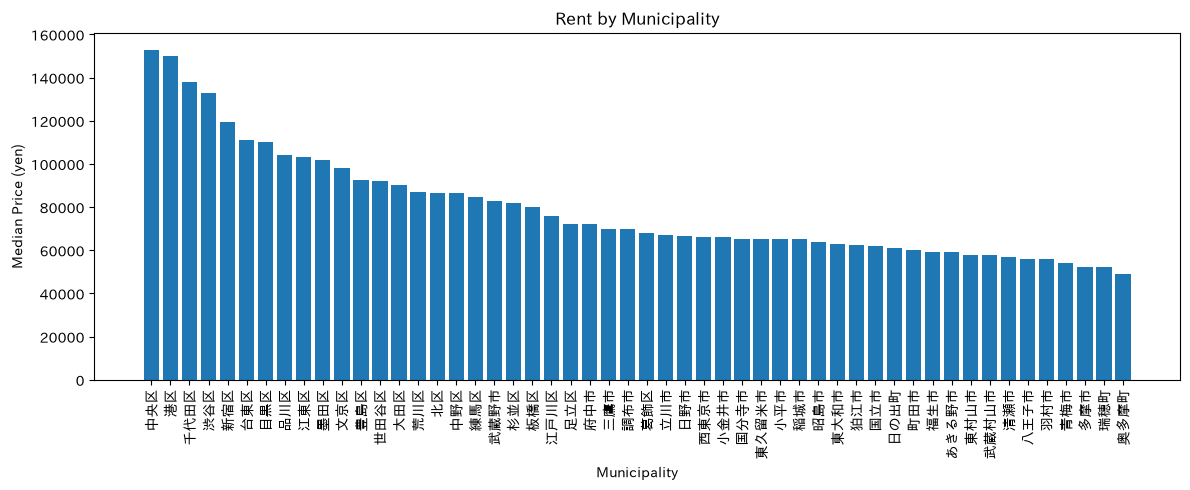

In [8]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # Adds Japanese font support to Matplotlib

median_rent = (
    df.groupby("municipality")["Price_yen"]
      .median()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))
plt.bar(median_rent.index, median_rent.values)

plt.xticks(rotation=90)
plt.xlabel("Municipality")
plt.ylabel("Median Price (yen)")
plt.title("Rent by Municipality")
plt.tight_layout()
plt.show()

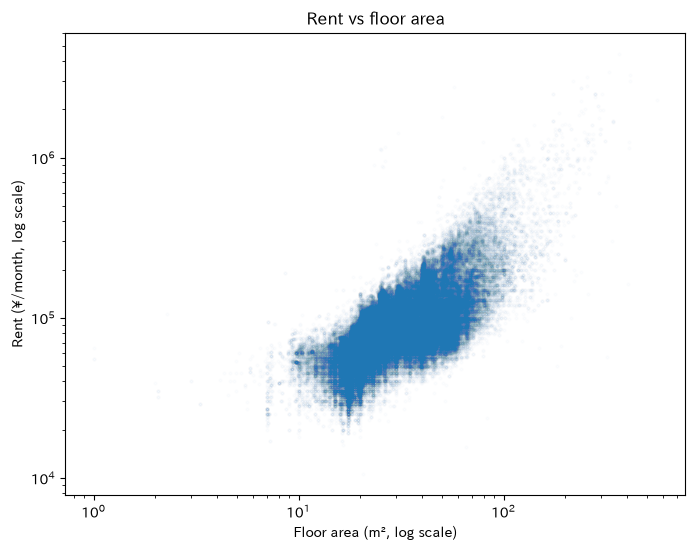

183490 0.6818015365346907


In [10]:
d = df[(df["area_m2"] > 0) & (df["Price_yen"] > 0)]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(d["area_m2"], d["Price_yen"], s=4, alpha=0.01)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Floor area (m², log scale)")
ax.set_ylabel("Rent (¥/month, log scale)")
ax.set_title("Rent vs floor area")
plt.show()

print(len(d), np.corrcoef(np.log(d["area_m2"]), np.log(d["Price_yen"]))[0, 1])

TypeError: Axes.hist() got multiple values for argument 'bins'

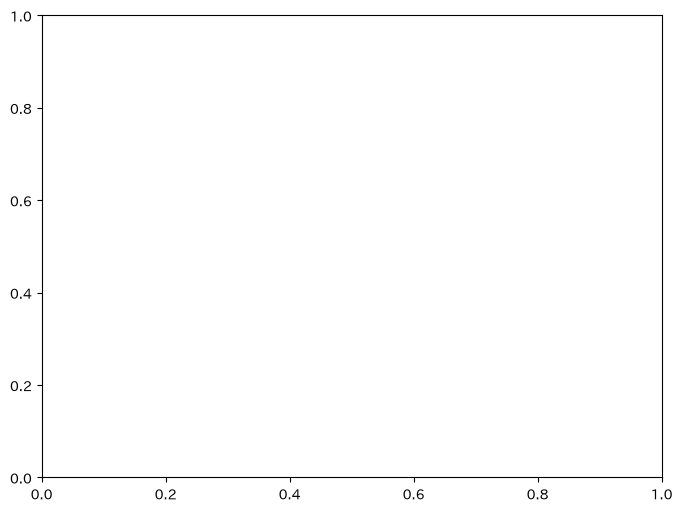

In [14]:
# Walking time vs rent, limited to 20 minutes histogram

d_filtered = d[
    (d["walk_min_nearest"] <= 20) &
    d["walk_min_nearest"].notna() &
    d["Price_yen"].notna()
]

fig, ax = plt.subplots(figsize=(8, 6))

h = ax.hist(
    d_filtered["walk_min_nearest"],
    d_filtered["Price_yen"],
    bins=[np.arange(0.5, 21.5, 1), 30],
    cmap="viridis"
)

fig.colorbar(h[3], ax=ax, label="Count")
ax.set_xlabel("Walking time (minutes)")
ax.set_ylabel("Rent (¥/month)")
ax.set_title("Rent vs walking time")
plt.tight_layout()
plt.show()

print(len(d_filtered))